<!-- Before Cell 1 -->
**Importing required libraries and loading data:**  
This cell imports necessary libraries and loads all CSV files into pandas DataFrames.


In [12]:
import pandas as pd
import numpy as np
import random
from deap import base, creator, tools, algorithms

# Example CSVs
students_df = pd.read_csv('students.csv')            # student_id, course_id
courses_df = pd.read_csv('courses.csv')              # course_id, instructor_id
instructors_df = pd.read_csv('instructors.csv')      # instructor_id, name
classrooms_df = pd.read_csv('classrooms.csv')        # classroom_id, capacity
timeslots_df = pd.read_csv('timeslots.csv')          # timeslot_id, date, time
schedule_df = pd.read_csv("schedule.csv")

<!-- Before Cell 2 -->
**Creating mapping dictionaries and entity lists:**  
This cell creates useful mappings (e.g., student to courses, course to instructor) and lists of all entities for scheduling.


In [13]:
# Student → list of courses
student_course_map = schedule_df.groupby('student_id')['course_id'].apply(list).to_dict()

# Instructor → courses
instructor_courses = schedule_df.groupby('instructor_id')['course_id'].unique().apply(list).to_dict()

# Course → instructor
course_instructor = schedule_df.drop_duplicates('course_id').set_index('course_id')['instructor_id'].to_dict()

# Course → number of students
course_student_count = schedule_df.groupby('course_id')['student_id'].nunique().to_dict()

# Classroom capacity
classroom_capacities = dict(zip(classrooms_df['classroom_id'], classrooms_df['capacity']))

# Entity lists
courses = list(course_student_count.keys())
students = students_df['student_id'].unique().tolist()
instructors = instructors_df['instructor_id'].unique().tolist()
classrooms = classrooms_df['classroom_id'].unique().tolist()
timeslots = timeslots_df['timeslot_id'].unique().tolist()


<!-- Before Cell 3 -->
**Defining the fitness evaluation function:**  
This function calculates penalties for student exam conflicts and classroom capacity violations.


In [14]:
def evaluate(individual):
    """
    Evaluates the fitness of an individual. Penalizes student conflicts and classroom capacity violations.
    """
    # Create a course schedule dictionary: course_id -> (timeslot, classroom)
    course_schedule = dict(zip(courses, individual))
    
    penalty = 0
    
    # 1. Check for student conflicts (2 exams at the same time)
    for student, enrolled_courses in student_course_map.items():
        seen = {}  # Store timeslot for each student
        for course in enrolled_courses:
            if course in course_schedule:
                timeslot, _ = course_schedule[course]  # Unpack timeslot and classroom
                if timeslot in seen:
                    penalty += 1  # Student has 2 exams at the same time
                seen[timeslot] = course

    # 2. Check for classroom capacity issues
    for i, (timeslot, classroom) in enumerate(individual):
        course_id = courses[i]
        enrolled = course_student_count.get(course_id, 0)  # Get number of students for the course
        capacity = classroom_capacities.get(classroom, 0)  # Get the classroom's capacity
        if enrolled > capacity:
            penalty += 1  # Overcrowded classroom

    # The fitness value is negative because we want to minimize penalties (fewer conflicts = higher fitness)
    return (-penalty,)


<!-- Before Cell 4 -->
**Setting up the genetic algorithm components:**  
This cell defines the genetic representation, mutation, crossover, and selection methods for the DEAP toolbox.


In [15]:

from deap import base, creator, tools
import random

# Create the genetic representation
if not hasattr(creator, "FitnessMax"):
    creator.create("FitnessMax", base.Fitness, weights=(1.0,))

if not hasattr(creator, "Individual"):
    creator.create("Individual", list, fitness=creator.FitnessMax)
    
# Define toolbox
toolbox = base.Toolbox()

# Gene: (timeslot, classroom)
def random_assignment():
    return (random.choice(timeslots), random.choice(classrooms))

toolbox.register("individual", tools.initRepeat, creator.Individual, random_assignment, n=len(courses))
toolbox.register("population", tools.initRepeat, list, toolbox.individual)

# Define mutate_individual to mutate both timeslot and classroom
def mutate_individual(individual, indpb=0.2):
    for i in range(len(individual)):
        if random.random() < indpb:
            individual[i] = (random.choice(timeslots), random.choice(classrooms))
    return (individual,)

# Register mutation and evaluation functions
toolbox.register("mutate", mutate_individual)
toolbox.register("evaluate", evaluate)

# Register crossover and selection methods
toolbox.register("mate", tools.cxTwoPoint)
toolbox.register("select", tools.selTournament, tournsize=3)


<!-- Before Cell 5 -->
**Running the genetic algorithm:**  
This cell runs the evolutionary process for a set number of generations to optimize the exam schedule.


In [16]:
# Create a population of 100 individuals
population = toolbox.population(n=100)

# Number of generations
NGEN = 50

for gen in range(NGEN):
    offspring = tools.selTournament(population, len(population), tournsize=3)
    offspring = list(map(toolbox.clone, offspring))

    # Apply crossover and mutation
    for child1, child2 in zip(offspring[::2], offspring[1::2]):
        if random.random() < 0.7:  # Crossover probability
            toolbox.mate(child1, child2)
            del child1.fitness.values
            del child2.fitness.values
    
    for mutant in offspring:
        if random.random() < 0.2:  # Mutation probability
            toolbox.mutate(mutant)
            del mutant.fitness.values

    # Evaluate fitness
    fits = list(map(toolbox.evaluate, offspring))

    # Update fitness values
    for ind, fit in zip(offspring, fits):
        ind.fitness.values = fit

    # Replace population with the offspring
    population[:] = offspring


<!-- Before Cell 6 -->
**Extracting the best schedule from the final population:**  
This cell retrieves the best individual (schedule) after the genetic algorithm finishes.


In [17]:
# After the genetic algorithm runs through all generations
# Get the best individual from the final population
best_ind = tools.selBest(population, 1)[0]

# Now you can iterate over the best individual
final_schedule = []
for i, (timeslot, classroom) in enumerate(best_ind):
    course_id = courses[i]
    instructor_id = course_instructor.get(course_id, "Unknown")
    final_schedule.append({
        'course_id': course_id,
        'instructor_id': instructor_id,
        'timeslot': timeslot,
        'classroom': classroom
    })

# `final_schedule` now contains the optimized schedule for the best individual.


<!-- Before Cell 7 -->
**Saving and displaying the optimized schedule:**  
This cell saves the final schedule to a CSV file and prints the first few rows.


In [18]:
final_schedule = []
for i, (timeslot, classroom) in enumerate(best_ind):
    course_id = courses[i]
    instructor_id = course_instructor.get(course_id, "Unknown")
    final_schedule.append({
        "course_id": course_id,
        "instructor_id": instructor_id,
        "timeslot_id": timeslot,
        "classroom_id": classroom
    })

final_schedule_df = pd.DataFrame(final_schedule)
final_schedule_df.to_csv("optimized_schedule.csv", index=False)
print(final_schedule_df.head())


   course_id                         instructor_id  timeslot_id  classroom_id
0          1  ba2adea1-5399-4c45-9c94-9f26f726f62e           48            24
1          2  cd3a4bbc-f36c-4e3d-9158-9a39dcff7644           16            11
2          3  7fa4b44f-6167-4bfe-b42b-5494a85f17c0           25            20
3          4  a12b297c-6ca7-436c-8318-08b5a05e1eea           53            18
4          5  cd3a4bbc-f36c-4e3d-9158-9a39dcff7644           26            25


<!-- Before Cell 8 -->
**Merging schedule with timeslot details:**  
This cell merges the schedule with timeslot information for better readability.


In [19]:


# Assuming timeslots_df contains ['timeslot_id', 'day', 'start_time', 'end_time']
final_schedule_df = final_schedule_df.merge(timeslots_df, on='timeslot_id', how='left')
final_schedule_df['timeslot'] = final_schedule_df['day'] + ' ' + final_schedule_df['start_time'] + '-' + final_schedule_df['end_time']


<!-- Before Cell 9 -->
**Visualizing the exam schedule by timeslot:**  
This cell creates a bar plot to visualize the distribution of exams across timeslots.


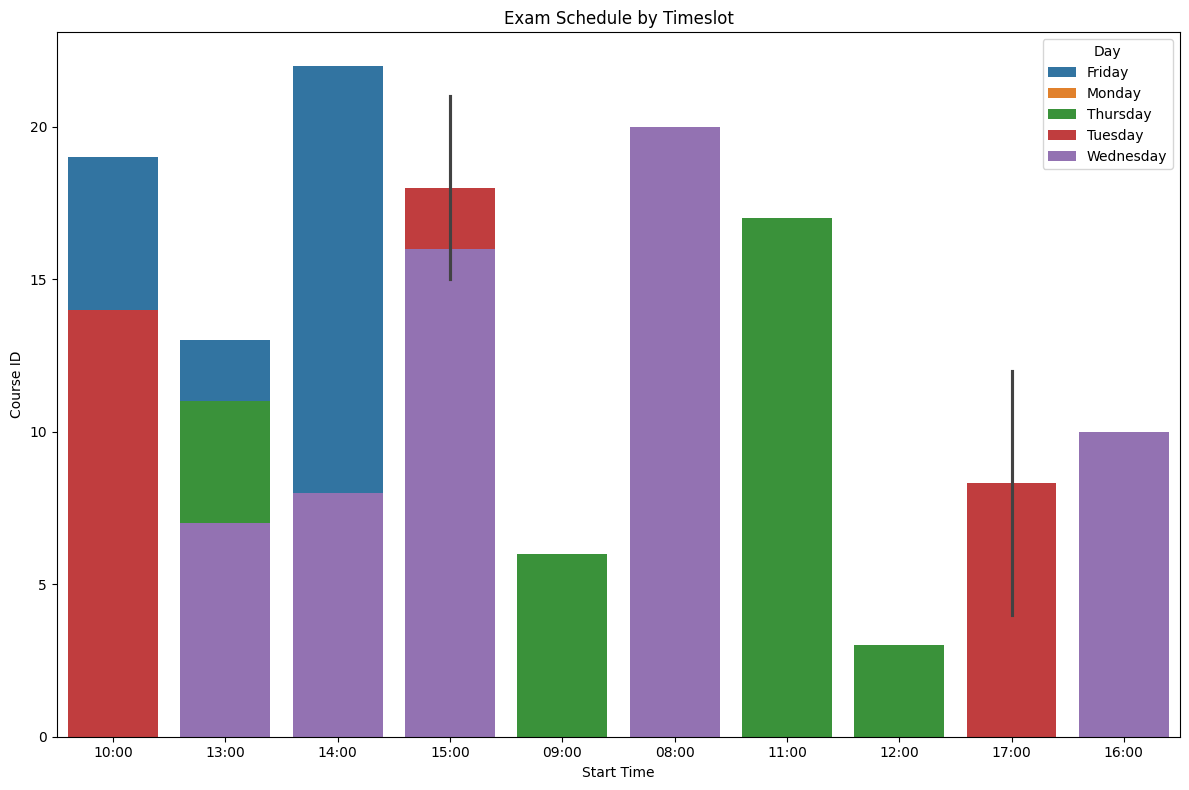

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

# Sort for better visuals
final_schedule_df = final_schedule_df.sort_values(by=['day', 'start_time'])

# Set up plot size
plt.figure(figsize=(12, 8))

# Bar plot: Course vs Timeslot
sns.barplot(
    data=final_schedule_df,
    y='course_id', 
    x='start_time',
    hue='day',
    dodge=False
)

plt.title("Exam Schedule by Timeslot")
plt.xlabel("Start Time")
plt.ylabel("Course ID")
plt.legend(title='Day')
plt.tight_layout()
plt.show()



<!-- Before Cell 10 -->
**Creating a timetable pivot table:**  
This cell creates a pivot table showing which courses are scheduled in each classroom and timeslot.


In [29]:
# Create a pivot table: rows = classroom, columns = timeslot, values = course_id
timetable = final_schedule_df.pivot_table(
    index='classroom_id',
    columns='timeslot',
    values='course_id',
    aggfunc=lambda x: ', '.join(str(v) for v in x)
).fillna('')


<!-- Before Cell 11 -->
**Visualizing the timetable as a heatmap:**  
This cell displays the timetable as a heatmap, with course IDs annotated in each cell.


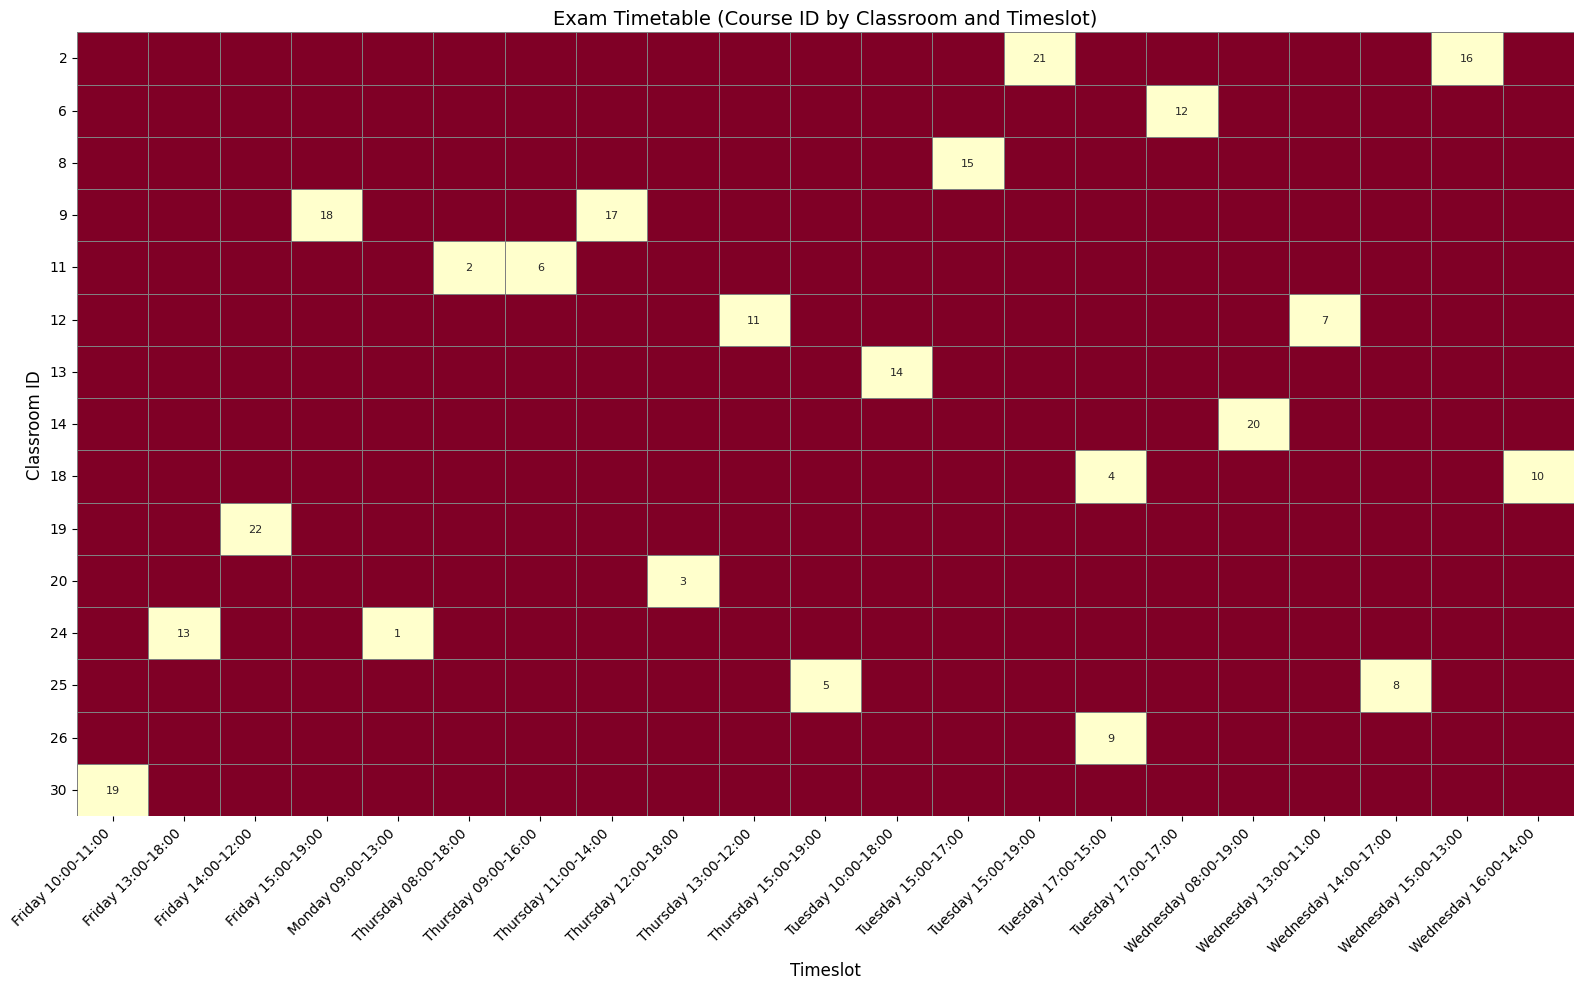

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 10))
plt.title('Exam Timetable (Course ID by Classroom and Timeslot)', fontsize=14)

# Show the timetable as a heatmap with annotations
import seaborn as sns

# Plot the heatmap with course_id as annotations
sns.heatmap(
    timetable.isin(['']),  # Boolean to control background (empty slots)
    cbar=False,
    cmap='YlOrRd',
    linewidths=0.5,
    linecolor='gray',
    annot=timetable, 
    fmt='', 
    annot_kws={"size": 8}
)

plt.xlabel("Timeslot", fontsize=12)
plt.ylabel("Classroom ID", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()
